# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vivian, Rahil, Yifan

**Date:** 11/10/2026

In [1]:
# Your Phase 1 solution to the problem goes here.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv('./data/pierce_county_house_sales.csv')
print(df.shape)
df.info()
df.isna().sum()

(16814, 19)
<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  

sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64

In [2]:
# Question 1

df['waterfront'] = df['waterfront_type'].notna().astype(int)
df['view'] = df['view_quality'].notna().astype(int)
df['age'] = 2020 - df['year_built']
df = df.drop(columns=['sale_date', 'year_built', 'waterfront_type', 'view_quality', 'interior', 'utility_sewer'])
df = df.dropna()
df = df[(df['sale_price'] >= 50000) & (df['bedrooms'] > 0) & (df['bedrooms'] <= 10) & (df['bathrooms'] > 0)]
print(df.shape)

(16716, 16)


                               count           mean            std      min  \
sale_price                   16716.0  461730.301508  231626.981401  50000.0   
house_square_feet            16716.0    1884.712790     757.614278    200.0   
attic_finished_square_feet   16716.0      24.831718     101.864554      0.0   
basement_square_feet         16716.0     168.251017     429.572444      0.0   
attached_garage_square_feet  16716.0     365.451184     286.126811      0.0   
detached_garage_square_feet  16716.0      38.465123     165.100339      0.0   
fireplaces                   16716.0       0.891481       0.595885      0.0   
stories                      16716.0       1.560780       0.510567      0.0   
bedrooms                     16716.0       3.288287       0.857469      1.0   
bathrooms                    16716.0       2.324180       0.821352      1.0   
waterfront                   16716.0       0.031766       0.175382      0.0   
view                         16716.0       0.054379 

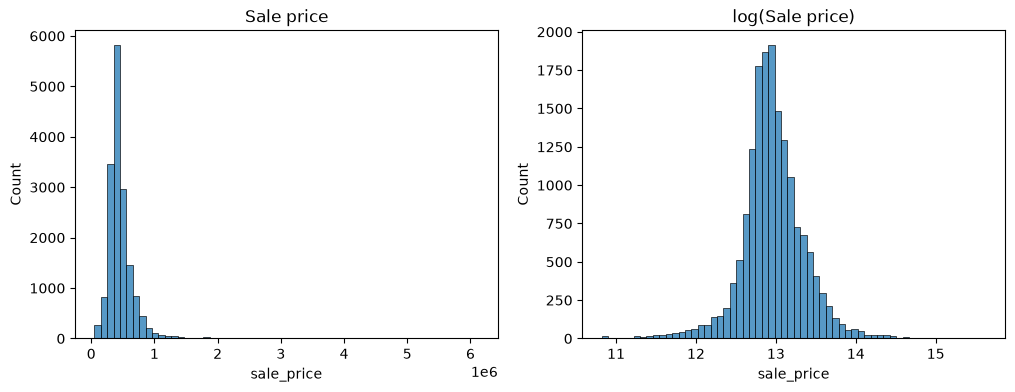

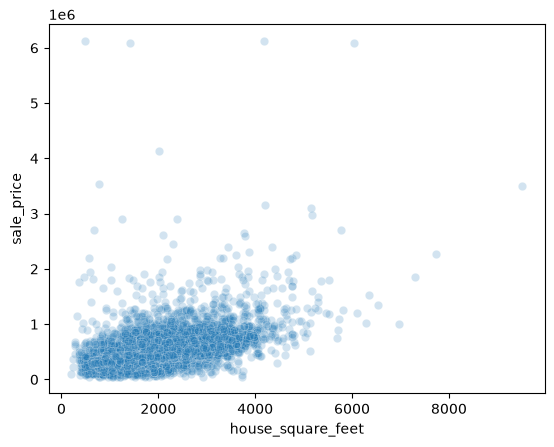

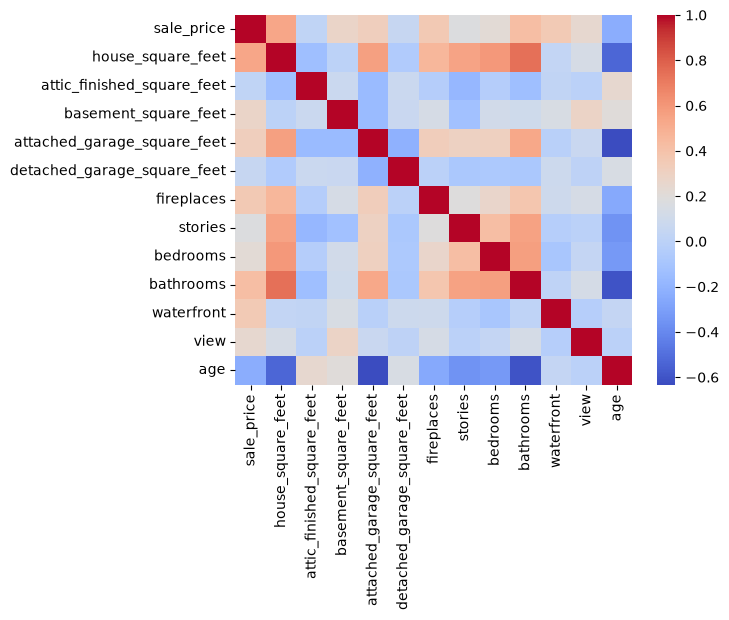

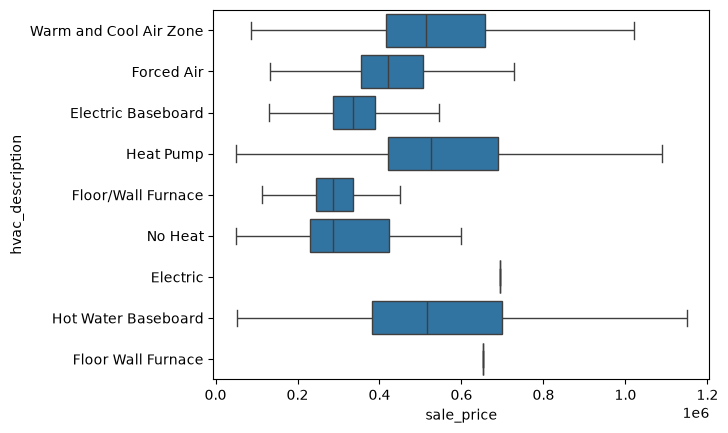

age                           -0.232211
attic_finished_square_feet     0.023703
detached_garage_square_feet    0.052764
stories                        0.171376
bedrooms                       0.220851
view                           0.246688
basement_square_feet           0.276330
attached_garage_square_feet    0.318548
waterfront                     0.353937
fireplaces                     0.357748
bathrooms                      0.423388
house_square_feet              0.539559
sale_price                     1.000000
Name: sale_price, dtype: float64
waterfront
0    415000.0
1    725000.0
Name: sale_price, dtype: float64
view
0    410000.0
1    665020.0
Name: sale_price, dtype: float64


In [3]:
# Question 1

print(df.describe().T)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['sale_price'], bins=60, ax=ax[0]).set_title('Sale price')
sns.histplot(np.log(df['sale_price']), bins=60, ax=ax[1]).set_title('log(Sale price)')
plt.show()

sns.scatterplot(data=df, x='house_square_feet', y='sale_price', alpha=0.2)
plt.show()

sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm')
plt.show()

sns.boxplot(data=df, x='sale_price', y='hvac_description', showfliers=False)
plt.show()

print(df.select_dtypes('number').corr()['sale_price'].sort_values())
print(df.groupby('waterfront')['sale_price'].median())
print(df.groupby('view')['sale_price'].median())

Question 1: Waterfront and View were converted to binary variables where either the house has them or doesn't have them at all. Rows with missing values and invalid data (price less than $50k, 0 bedrooms/bathrooms, >10 bedrooms) were excluded from the data, leading to 16,716 transactions. "Year built" was converted to "age" (2020 - year built), while columns that almost consist of the same value ("Interior", "Utility Sewer") and "Sales Date" were removed. The distribution of sale price is highly right skewed (median $417k, max $6.1M), whereas the log(price) distribution looks more normally distributed. House square footage shows the most positive correlation with the sale price (Pearson Correlation coefficient: r = 0.54), followed by Bathrooms (0.42), Fireplaces (0.36), and Waterfront (0.35). Houses that have waterfront or view have significantly higher prices (median $725k and $665k respectively, compared to $415k).

In [4]:
# Question 2

common = df['exterior'].value_counts().index[:4]
df['exterior'] = df['exterior'].where(df['exterior'].isin(common), 'Other')
df = pd.get_dummies(df, columns=['hvac_description', 'exterior', 'roof_cover'], drop_first=True, dtype=int)
print(df.shape)
df.head()

(16716, 30)


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,bedrooms,bathrooms,...,hvac_description_Warm and Cool Air Zone,exterior_Frame Stucco,exterior_Frame Vinyl,exterior_Masonry Common Brick,exterior_Other,roof_cover_Composition Shingle,roof_cover_Concrete Tile,roof_cover_Formed Seam Metal,roof_cover_Preformed Metal,roof_cover_Wood Shake
0,380000,2157,0,0,528,0,0,2,3,3,...,1,0,0,0,0,1,0,0,0,0
1,383000,2238,0,0,396,0,0,2,4,3,...,0,0,0,0,0,1,0,0,0,0
2,419900,1452,0,0,0,0,1,1,3,2,...,0,0,0,0,0,0,0,0,0,0
3,251660,832,0,0,0,0,0,1,2,1,...,0,0,1,0,0,1,0,0,0,0
4,500000,1780,0,384,484,0,1,1,3,2,...,0,0,0,0,0,1,0,0,0,0


Question 2: One-hot encoding was applied on columns "HVAC," "Exterior," and "Roof" with `drop_first=True` in order to avoid the dummy variable trap. The less common values for "Exterior" were assigned to "Other," thus avoiding the instability of coefficients. Both "Waterfront" and "View" are binary indicators (variables/columns), while "Year Built" is transformed to Age.

In [5]:
# Question 3

y = df['sale_price']
X = df.drop(columns='sale_price')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)
print(X_train.shape, X_test.shape)

(13372, 29) (3344, 29)


Question 3: Using the `train_test_split` function with the `random_state=100`, the data is split into two sets with an 80-20 ratio, such that the first set (training set) comprises 13,372 houses while the second set (test set) contains 3,344 houses. The test set will be kept separate for use during evaluation of the models, so that it gives an honest measure of performance on new data.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [6]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]